# Clustering et optimisation

## Cahier des charges

- Il existe des installations à risque réparties géographiquement (voir graphique plus bas).
- On souhaite déployer des centres avec un rayon d'intervention de 3 km afin de couvrir l'ensemble des installations.

**Problème** : identifier les positions des centres à déployer et les installations qu'ils couvrent, avec deux approches :

- déployer des centres uniquement sur des installations existantes,
- pouvoir déployer de nouveaux centres avec une position arbitraire.

**Objectif** : minimiser le nombre de centres à déployer.

## Répartition géographique des installations

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import set_config

set_config(transform_output="pandas")
plt.rcParams['figure.figsize'] = [6, 4]

In [2]:
# seuil de portée, en km
T = 3

### Jeu de données no. 1

- 4 points
- solution avec 2 clusters ($r \leq 3$)

In [3]:
df1 = pd.DataFrame({
    "x": [0, 4, 1, 6],
    "y": [3, 0, 5, 2],
})

In [4]:
from scipy.spatial import distance_matrix

In [5]:
# calcul des distances pour chaque paire de points d'un même cluster (matrice de distances)
m1 = distance_matrix(df1, df1)
m1

array([[0.        , 5.        , 2.23606798, 6.08276253],
       [5.        , 0.        , 5.83095189, 2.82842712],
       [2.23606798, 5.83095189, 0.        , 5.83095189],
       [6.08276253, 2.82842712, 5.83095189, 0.        ]])

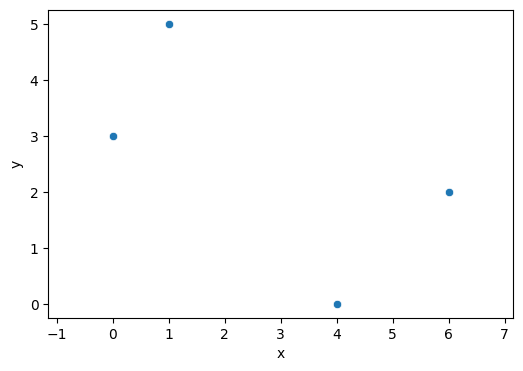

In [6]:
sns.scatterplot(df1, x="x", y="y")
plt.axis("equal")
plt.show()

### Jeu de données no. 2

- 114 points
- solution avec 7 clusters ($r \leq 3$)
- solution avec 6 clusters ($d \leq 3 \sqrt{3}$)

In [7]:
np.random.seed(2)
x = np.random.multivariate_normal([3, 7], 3*np.identity(2), 24)
x = np.concatenate([x, np.random.multivariate_normal([9, 5], 3*np.identity(2), 50)])
x = np.concatenate([x, np.random.multivariate_normal([12, 6], 0.5*np.identity(2), 20)])
x = np.concatenate([x, np.random.multivariate_normal([2, 7], 0.8*np.identity(2), 20)])
df2 = pd.DataFrame(x, columns=["x", "y"])
# matrice de distance
m2 = distance_matrix(df2, df2)

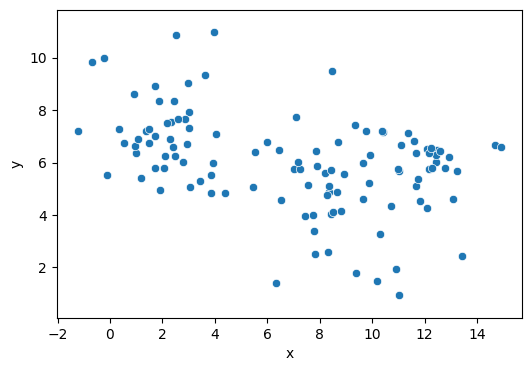

In [8]:
sns.scatterplot(df2, x="x", y="y")
plt.axis("equal")
plt.show()

In [9]:
# choix du cas d'étude
# df, dist_mat = df1, m1
df, dist_mat = df2, m2

**Question** : Quels algorithmes connaissez-vous pour répondre à ce type de problème, où les clusters sont contraints par une largeur maximale (diamètre ou rayon) ?

<div class="alert alert-success">
<p>La classification ascendante hiérarchique permet de définir une distance de coupure qui correspond à une distance maximum au sein d'un cluster dans le cas du complete-linkage.</p>
<p>Pour les curieux, il existe l'équivalent pour la notion de rayon, appelé <a href="https://en.wikipedia.org/wiki/Hierarchical_clustering#Cluster_Linkage">mini-max linkage</a>, mais qui n'est pas implémenté dans scikit-learn.</p>
</div>

**Question** : S'il s'agit d'un algorithme contraint par une valeur de diamètre, quelle borne peut-on fixer pour garantir que le rayon des clusters soit au plus égal à T (ici 3) ?

Le [théorème de Jung](https://fr.wikipedia.org/wiki/Th%C3%A9or%C3%A8me_de_Jung) dit que, dans un espace euclidien de dimension $n$, tout ensemble de diamètre $d$ est inclus dans une boule de rayon $r \leq d \sqrt{\dfrac{n}{2(n + 1)}}$.  
En dimension 2, cette inégalité donne : $r \leq \dfrac{d}{\sqrt{3}}$, donc $d \leq \sqrt{3}\;T \Rightarrow r \leq T$.  
Remarque : dans le cas général (espace non euclidien), la seule manière de garantir $r \leq T$ est de fixer $d \leq T$, ce qui est souvent assez pessimiste.

**Question** : Calculer et visualiser les groupes et les centres associés répondant au problème en vous basant sur un algorithme de clustering.  
Pour calculer le cercle circonscrit à un ensemble de points, vous pouvez utiliser le paquet [*miniball*](https://github.com/marmakoide/miniball).

**Question** : Vous semble-t-il possible de formuler un problème d'optimisation répondant au cahier des charges ?  
Quelle fonction objectif et quelles contraintes définiriez-vous ?

<div class="alert alert-success">
<h2>Solution 1 : classification ascendante hiérarchique (complete-link)</h2>
<ul>
<li>la prise en compte de la distance maximale entre deux points d'un cluster (complete-link) permet d'en borner le diamètre (ici $3 \sqrt{3}$ km)</li>
<li>la solution ne garantit pas de minimiser le nombre de clusters</li>
</ul>
</div>

In [10]:
from sklearn.cluster import AgglomerativeClustering

In [11]:
aggl = AgglomerativeClustering(n_clusters=None, distance_threshold=np.sqrt(3)*T, linkage="complete")
labels_agg = aggl.fit_predict(df)
df["label"] = labels_agg
print(f"nombre de clusters : {len(np.unique(labels_agg))}")

nombre de clusters : 9


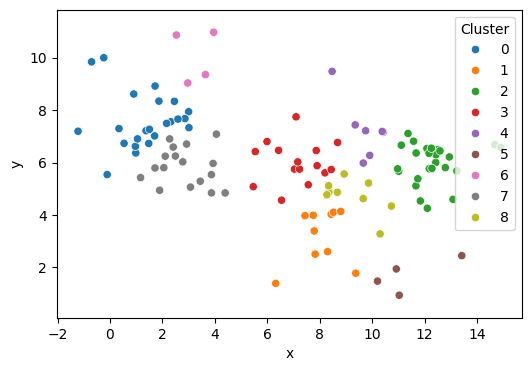

In [12]:
sns.scatterplot(df, x="x", y="y", hue="label", palette="tab10")
plt.legend(title="Cluster")
plt.axis("equal")
plt.show()

In [13]:
import miniball

In [14]:
# calcul des centres
bounding_spheres = []
for l in df["label"].drop_duplicates().sort_values():
    c, r = miniball.get_bounding_ball(df[df["label"] == l][["x", "y"]].to_numpy())
    bounding_spheres.append((c, np.sqrt(r)))
    print(f"Cluster {l}: r = {np.sqrt(r):.4f}")

Cluster 0: r = 2.4165
Cluster 1: r = 1.8614
Cluster 2: r = 2.0110
Cluster 3: r = 1.8159
Cluster 4: r = 1.8467
Cluster 5: r = 1.6784
Cluster 6: r = 1.1002
Cluster 7: r = 1.7598
Cluster 8: r = 1.3521


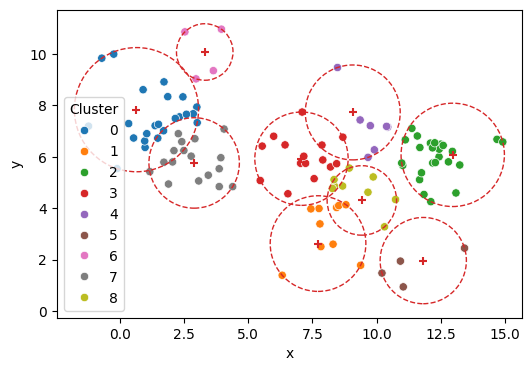

In [15]:
sns.scatterplot(df, x="x", y="y", hue="label", palette="tab10")
plt.legend(title="Cluster")
plt.axis("equal")
for c, r in bounding_spheres:
    plt.scatter(c[0], c[1], c="tab:red", marker="+")
    plt.gca().add_patch(plt.Circle(c, r, color="tab:red", fill=False, ls="--"))

<div class="alert alert-success">
<h1>Solution 2 : programmation linéaire (avec contrainte de rayon sur un pseudo-médoïde, c-à-d sans nouvelle installation)</h1>
<p>On formule le problème comme un problème d'optimisation.</p>
<ul>
<li>$r[i, j]$ indique que le point i appartient au cluster de centre j</li>
<li>
<p>$r[i, i]$ indique que le point i est le <em>centre</em> de son cluster</p>
</li>
<li>
<p>la solution garantit de minimiser le nombre de clusters (sous réserve de convergence par le solveur)</p>
</li>
<li>la solution garantit qu'il existe un pseudo-médoïde pour lequel chaque élément du cluster se trouve dans un rayon de 3 km</li>
</ul>
</div>

In [16]:
from ortools.linear_solver import pywraplp

In [17]:
solver = pywraplp.Solver.CreateSolver("SAT")

r = [[solver.BoolVar(f"r_{i}{j}") for i in range(len(df))] for j in range(len(x))]

# fonction objectif : minimizer le nombre de centres (i.e. le nombre de clusters)
solver.Minimize(solver.Sum(r[i][i] for i in range(len(df))))

# contrainte : chaque élément doit appartenir à un et un seul cluster : sum(r[i][:]) == 1
for i in range(len(df)):
    solver.Add(solver.Sum(r[i][j] for j in range(len(df))) == 1)

# contrainte : si i appartient au cluster de centre j, alors j appartient au même cluster : r[i][j] == 1 => r[j][j] == 1
for j in range(len(df)):
    for i in range(len(df)):
        solver.Add(r[j][j] >= r[i][j])

# contrainte : si d(i, j) > seuil, alors i et j ne peuvent pas appartenir au même cluster : d(i, j) > thr => r[i][j] == 0
for j in range(len(df)):
    for i in range(len(df)):
        if dist_mat[i][j] > T:
            solver.Add(r[i][j] == 0)

status = solver.Solve()

assert status == pywraplp.Solver.OPTIMAL
print("objectif =", solver.Objective().Value())
medoids = [i for i in range(len(df)) if r[i][i].solution_value()]
df["label"] = np.argmin(dist_mat[medoids], axis=0)
print(f"pseudo-médoïdes sélectionnés: {medoids}")

objectif = 7.0
pseudo-médoïdes sélectionnés: [16, 17, 18, 33, 53, 64, 67]


In [18]:
for medoid in medoids:
    print(f"Cluster with pseudo-medoid {medoid} has radius {dist_mat[:, df['label'] == df.loc[medoid, 'label']].max(axis=1).min():.4f}")

Cluster with pseudo-medoid 16 has radius 2.7646
Cluster with pseudo-medoid 17 has radius 2.1728
Cluster with pseudo-medoid 18 has radius 2.7040
Cluster with pseudo-medoid 33 has radius 2.4248
Cluster with pseudo-medoid 53 has radius 2.5267
Cluster with pseudo-medoid 64 has radius 2.5470
Cluster with pseudo-medoid 67 has radius 2.7195


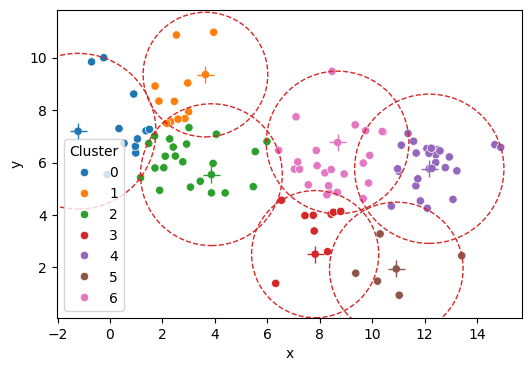

In [19]:
# affichage des médoïdes
sns.scatterplot(df, x="x", y="y", hue="label", palette="tab10")
sns.scatterplot(df.loc[medoids], x="x", y="y", hue="label", palette="tab10", s=150, marker="+", legend=False)
plt.legend(title="Cluster")
plt.axis("equal")
for medoid in medoids:
    l = df.loc[medoid, "label"]
    r = dist_mat[medoid, df["label"] == df.loc[medoid, "label"]].max()
    c = df.loc[medoid, ["x", "y"]]
    plt.gca().add_patch(plt.Circle((c["x"], c["y"]), r, color='tab:red', fill=False, ls='--'))
plt.show()

<div class="alert alert-success">
<h2>Solution 3 : programmation par contraintes (sans médoïde, i.e., avec nouvelle installation potentielle)</h2>
<p>On formule le problème comme un problème d'optimisation.</p>
<ul>
<li>
<p>$l[i]$ est le numéro de cluster (label) du point i</p>
</li>
<li>
<p>la solution garantit de minimiser le nombre de clusters (sous réserve de convergence par le solveur)</p>
</li>
<li>la solution ne garantit pas qu'il existe un médoïde pour lequel chaque élément du cluster se trouve dans un rayon de 3 km</li>
</ul>
</div>

In [20]:
from ortools.sat.python import cp_model

In [21]:
n = len(df)
m = cp_model.CpModel()
# les labels sont des entiers compris entre 0 et n-1
l = [m.NewIntVar(0, n - 1, f'l_{i}') for i in range(n)]

# on calcule la matrice de distances puis une matrice booléenne de compatibilité
# i.e. compat[i, j] indique si les points i et j sont distants de moins de 2*seuil
compat = dist_mat <= np.sqrt(3)*T
# garantie d'existance d'un centre (dans le plan avec distance Euclidienne)
#compat = distances <= np.sqrt(3)*T

# la section suivante est optionnelle :
# pour accélérer le calcul, on casse les symétries en fixant quelques labels évidents
# (par étude des incompatibilités paire à paire)
# en particulier : l[0] = 0
reflist = []
label = 0
for i in range(n):
    comp = False
    for ref in reflist:
        if compat[ref, i]:
            comp = True
            break;
    if not comp:
        reflist.append(i)
        m.Add(l[i] == label)
        label += 1
# fin de section optionnelle
print(reflist)

# pour chaque paire de points incompatibles, on indique que leurs labels doivent être différents
for j in range(n):
    for i in range(j):
        if not compat[i,j]:
            m.Add(l[i] != l[j])

# la variable objectif est k, égale à la valeur du label le plus grand, qu'on cherche à minimiser
k = m.NewIntVar(0, n - 1, 'k')
m.AddMaxEquality(k, l)
m.Minimize(k)

solver = cp_model.CpSolver()
status = solver.Solve(m)

print(f'status: {solver.StatusName()}')
if status == cp_model.OPTIMAL or status == cp_model.FEASIBLE:
    k_sol = solver.Value(k)+1
    print(f'Found {k_sol} clusters:')
    labels_cp = [solver.Value(e) for e in l]
    df['label'] = labels_cp
    for label in range(k_sol):
        print(f'label {label}: {labels_cp.count(label)} element(s)')

[0, 24, 49, 72]


status: OPTIMAL
Found 6 clusters:
label 0: 27 element(s)
label 1: 25 element(s)
label 2: 13 element(s)
label 3: 28 element(s)
label 4: 9 element(s)
label 5: 12 element(s)


In [22]:
# calcul des centres
bounding_spheres = []
for l in df["label"].drop_duplicates().sort_values():
    c, r = miniball.get_bounding_ball(df[df["label"] == l][["x", "y"]].to_numpy())
    bounding_spheres.append((c, np.sqrt(r)))
    print(f"Cluster {l}: r = {np.sqrt(r):.4f}")

Cluster 0: r = 2.8971
Cluster 1: r = 2.6180
Cluster 2: r = 2.5829
Cluster 3: r = 2.8264
Cluster 4: r = 2.2398
Cluster 5: r = 2.5280


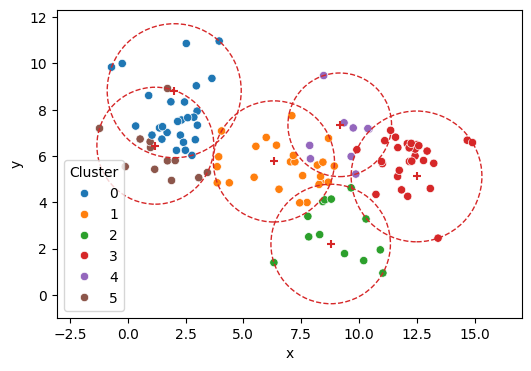

In [23]:
sns.scatterplot(df, x="x", y="y", hue="label", palette="tab10")
plt.legend(title="Cluster")
plt.axis("equal")
for c, r in bounding_spheres:
    plt.scatter(c[0], c[1], c="tab:red", marker="+")
    plt.gca().add_patch(plt.Circle(c, r, color="tab:red", fill=False, ls="--"))

<div class="alert alert-success">
<p>Dans cette dernière solution, il manquerait une réaffectation des éléments à leur centre le plus proche, car on observe que la solution proposée par le solveur ne répond pas tout à fait aux exigences usuelles de problèmes de clustering.<br />
La solution donnée (qui n'est pas unique) respecte néanmoins le cahier des charges.</p>
</div>

<div class="alert alert-success">
<p>Il existe également des techniques de résolution basées sur les graphes, et ce pour les deux problèmes :</p>
<ul>
<li>le clustering sous contrainte de diamètre est assimilé au problème de <a href="https://en.wikipedia.org/wiki/Clique_cover"><em>couverture par cliques minimale</em></a> dans les graphes,</li>
<li>le clustering sous contrainte de rayon est assimilé au problème <a href="https://en.wikipedia.org/wiki/Dominating_set"><em>d'ensemble dominant de cardinalité minimale</em></a> dans es graphes.</li>
</ul>
</div>